# Swahili News Topic Classification: fastText + BiGRU

Model 2 from `swahili_news_baseline.ipynb`. Same cleaning, same stratified split (`random_state=42`), same metrics. The classifier is a bidirectional GRU over pretrained Swahili fastText vectors.

The official test set is scored once, after the checkpoint is chosen on validation macro-F1.

Run this notebook on Google Colab with a GPU. Use Runtime → Change runtime type → T4 GPU, then Run all. The session downloads the Swahili fastText file (about 220 MB). Section 12 zips the checkpoint and metrics and downloads them, because Colab deletes the session disk when the runtime stops.


## 1. Setup

Colab already includes a CUDA build of PyTorch. Leave that build in place. A fresh `pip install torch` on Colab can replace it with a CPU wheel, and then the GPU sits idle.


In [1]:
# Do not install torch here. Colab's preinstalled build is the CUDA one.
%pip install -q datasets scikit-learn pandas matplotlib seaborn


You should consider upgrading via the '/Users/macbookpro/Documents/ALU/alu-machine_learning/swahili_txt_classification/.venv/bin/python -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
import gzip
import json
import random
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

SEED = 42
MAX_LEN = 256          # median article is 269 words; the 95th percentile is about 790
MIN_FREQ = 2
MAX_VOCAB = 50_000
MIN_OOV_KEEP = 5       # fastText misses that still occur often enough to learn
EMBED_DIM = 300
HIDDEN_DIM = 128
DROPOUT = 0.3
BATCH_SIZE = 64
EPOCHS = 6
PATIENCE = 2
LR = 1e-3
EMBED_LR = 1e-4
PAD, UNK = 0, 1

VEC_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.sw.300.vec.gz"
# Paths are relative to the repo root, whether this runs from notebooks/ or from Colab's /content.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = ROOT / "models"
RESULTS_DIR = ROOT / "results" / "bigru"
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
VEC_PATH = ROOT / "embeddings" / "cc.sw.300.vec.gz"
CKPT_PATH = MODELS_DIR / "swahili_bigru.pt"
METRICS_PATH = RESULTS_DIR / "bigru_metrics.json"
HISTORY_PATH = RESULTS_DIR / "bigru_history.json"
ERRORS_PATH = RESULTS_DIR / "bigru_errors.csv"

def mps_available():
    backend = getattr(torch.backends, "mps", None)
    return backend is not None and backend.is_available()

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if mps_available():
        torch.mps.manual_seed(seed)

set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Device: cuda |", torch.cuda.get_device_name(0))
elif mps_available():
    device = torch.device("mps")
    print("Device: mps")
else:
    device = torch.device("cpu")
    print("Device: cpu")
    print("No GPU detected. In Colab: Runtime → Change runtime type → T4 GPU, then rerun this notebook from the top.")

print("Working directory:", Path.cwd())


/Users/macbookpro/Documents/ALU/alu-machine_learning/swahili_txt_classification/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/macbookpro/Documents/ALU/alu-machine_learning/swahili_txt_classification/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Device: mps


## 2. Load the data

Same source as the baseline. The official test split stays untouched, and the validation set is cut from train.


In [3]:
try:
    ds = load_dataset("community-datasets/swahili_news")
except Exception as e:
    print("First attempt failed:", e)
    ds = load_dataset("swahili_news")

print(ds)
label_names = ds["train"].features["label"].names
print("Classes:", label_names)


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 22207
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7338
    })
})
Classes: ['uchumi', 'kitaifa', 'michezo', 'kimataifa', 'burudani', 'afya']


In [4]:
train_full = ds["train"].to_pandas()
test_df    = ds["test"].to_pandas()

train_full["label_name"] = train_full["label"].map(lambda i: label_names[i])
test_df["label_name"]    = test_df["label"].map(lambda i: label_names[i])

train_full.head()


,text,label,label_name
0,"Bodi ya Utalii Tanzania (TTB) imesema, itafan...",0,uchumi
1,"PENDO FUNDISHA-MBEYA RAIS Dk. John Magufuri, ...",1,kitaifa
2,Mwandishi Wetu -Singida BENKI ya NMB imetoa ms...,0,uchumi
3,"TIMU ya taifa ya Tanzania, Serengeti Boys jan...",2,michezo
4,Na AGATHA CHARLES – DAR ES SALAAM ALIYEKUWA K...,1,kitaifa


## 3. Preprocessing

Copied from the baseline so the rows that enter the split are the same. Light cleaning only: Swahili is agglutinative, and stemming or stopword removal without a proper tool throws away useful prefixes.


In [5]:
URL_RE   = re.compile(r"https?://\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+")
NONWORD  = re.compile(r"[^a-zA-Z\u00C0-\u017F'\s]")   # keep letters and apostrophes
SPACES   = re.compile(r"\s+")

def clean_text(t: str) -> str:
    t = t.lower()
    t = URL_RE.sub(" ", t)
    t = EMAIL_RE.sub(" ", t)
    t = NONWORD.sub(" ", t)
    t = SPACES.sub(" ", t).strip()
    return t

for df in (train_full, test_df):
    df["clean"] = df["text"].apply(clean_text)

# Drop duplicates and empties from train only (never alter the official test set)
before = len(train_full)
train_full = train_full[train_full["clean"].str.len() > 0].drop_duplicates(subset="clean").reset_index(drop=True)
print(f"Train: {before} -> {len(train_full)} after removing empties/duplicates")

# Check for leakage between train and test
leak = set(train_full["clean"]) & set(test_df["clean"])
print("Texts appearing in both train and test:", len(leak))


Train: 22207 -> 22185 after removing empties/duplicates
Texts appearing in both train and test: 46


## 4. Splits

Same rule as the baseline: stratified 90/10 of the official train set, seed 42. Test is the official test split.


In [6]:
train_df, val_df = train_test_split(
    train_full, test_size=0.10, stratify=train_full["label"], random_state=SEED
)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
pd.DataFrame({
    "train": train_df["label_name"].value_counts(normalize=True),
    "val":   val_df["label_name"].value_counts(normalize=True),
    "test":  test_df["label_name"].value_counts(normalize=True),
}).round(3)


Train: 19966 | Validation: 2219 | Test: 7338


,train,val,test
label_name,,,
kitaifa,0.457,0.457,0.456
michezo,0.269,0.269,0.272
burudani,0.098,0.098,0.096
kimataifa,0.084,0.084,0.082
uchumi,0.057,0.057,0.064
afya,0.035,0.035,0.030


## 5. Vocabulary and fastText vectors

Word vectors are the Common Crawl Swahili set from fastText, `cc.sw.300` (Grave et al., 2018, *Learning Word Vectors for 157 Languages*). Each word is a 300-dimensional vector. The file is a few hundred thousand rows; only rows that appear in the training vocabulary are kept.

Rules, fit on train only:

- `<pad>` is index 0 and `<unk>` is index 1
- a word must appear at least twice, and the list is capped at 50,000 types
- a training word that fastText does not contain keeps its own row only when it appears at least 5 times; rarer misses share `<unk>`
- words seen once are a small share of tokens, so folding them into `<unk>` costs little

Articles are cut to the first 256 tokens. That is just under the median length (269). A BiGRU reads every token in order, and the long tail (95th percentile near 790 words) adds a lot of compute for a topic decision that the opening of a news article usually already makes.


In [7]:
def build_vocab(texts, min_freq, max_size):
    counts = Counter()
    for text in texts:
        counts.update(text.split())
    kept = [w for w, c in counts.most_common() if c >= min_freq][: max_size - 2]
    stoi = {"<pad>": PAD, "<unk>": UNK}
    for w in kept:
        stoi[w] = len(stoi)
    return stoi, counts

def ensure_fasttext(path, url):
    if path.exists() and path.stat().st_size > 100_000_000:
        print(f"Using {path} ({path.stat().st_size / 1e6:.1f} MB)")
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading Swahili fastText vectors...")

    def hook(block, block_size, total):
        if total > 0 and (block % 200 == 0 or block * block_size >= total):
            print(f"  {min(block * block_size, total) / 1e6:.0f} / {total / 1e6:.0f} MB", flush=True)

    urllib.request.urlretrieve(url, path, hook)
    print(f"Saved {path} ({path.stat().st_size / 1e6:.1f} MB)")

def load_fasttext(path, wanted, dim):
    found = {}
    with gzip.open(path, "rt", encoding="utf-8", errors="ignore") as f:
        n_rows, file_dim = map(int, f.readline().split())
        if file_dim != dim:
            raise ValueError(f"expected dim {dim}, file has {file_dim}")
        print(f"Scanning {n_rows:,} fastText rows")
        for i, line in enumerate(f, 1):
            space = line.find(" ")
            if space <= 0:
                continue
            word = line[:space]
            if word not in wanted:
                continue
            vec = np.asarray(line[space + 1:].split(), dtype=np.float32)
            if vec.shape[0] != dim:
                continue
            found[word] = vec
            if len(found) == len(wanted):
                break
            if i % 100_000 == 0:
                print(f"  scanned {i:,} rows, matched {len(found):,}", flush=True)
    return found

stoi, counts = build_vocab(train_df["clean"], MIN_FREQ, MAX_VOCAB)
total_tokens = sum(counts.values())
hapax_tokens = sum(c for c in counts.values() if c == 1)
print(f"Candidate vocab: {len(stoi):,} (cap {MAX_VOCAB})")
print(f"Hapax tokens: {hapax_tokens / total_tokens:.1%} of train tokens")

ensure_fasttext(VEC_PATH, VEC_URL)
t0 = time.perf_counter()
wanted = set(stoi) - {"<pad>", "<unk>"}
found = load_fasttext(VEC_PATH, wanted, EMBED_DIM)
print(f"Matched {len(found):,} / {len(wanted):,} vocab words in {time.perf_counter() - t0:.1f}s")

# Drop rare fastText misses. Frequent misses keep a row and are learned from scratch.
final = {"<pad>": PAD, "<unk>": UNK}
n_ft, n_oov = 0, 0
for w, _idx in sorted(stoi.items(), key=lambda kv: kv[1]):
    if w in ("<pad>", "<unk>"):
        continue
    if w in found:
        final[w] = len(final)
        n_ft += 1
    elif counts[w] >= MIN_OOV_KEEP:
        final[w] = len(final)
        n_oov += 1
stoi = final
print(f"Final vocab: {len(stoi):,}  |  fastText rows: {n_ft:,}  |  learned OOV rows: {n_oov:,}")

rng = np.random.default_rng(SEED)
mean_vec = np.mean(np.stack(list(found.values())), axis=0).astype(np.float32)
matrix = np.tile(mean_vec, (len(stoi), 1))
matrix += rng.normal(0, 0.01, size=matrix.shape).astype(np.float32)
matrix[PAD] = 0.0
for w, vec in found.items():
    if w in stoi:
        matrix[stoi[w]] = vec
matrix = np.ascontiguousarray(matrix, dtype=np.float32)

# Token coverage on the truncated training articles
ft_hit = vocab_hit = n_tok = 0
ft_words = set(found)
for text in train_df["clean"]:
    for tok in text.split()[:MAX_LEN]:
        n_tok += 1
        if tok in ft_words:
            ft_hit += 1
        if tok in stoi and stoi[tok] != UNK:
            vocab_hit += 1
ft_coverage = ft_hit / n_tok
vocab_coverage = vocab_hit / n_tok
print(f"Train tokens (first {MAX_LEN}): fastText {ft_coverage:.1%}  |  in vocab {vocab_coverage:.1%}")

del found, ft_words
assert matrix.shape == (len(stoi), EMBED_DIM)
assert np.all(matrix[PAD] == 0)
assert "na" in stoi and np.linalg.norm(matrix[stoi["na"]]) > 0


Candidate vocab: 50,000 (cap 50000)
Hapax tokens: 1.5% of train tokens
Using embeddings/cc.sw.300.vec.gz (226.9 MB)
Scanning 387,963 fastText rows


Matched 31,745 / 49,998 vocab words in 3.0s
Final vocab: 45,348  |  fastText rows: 31,745  |  learned OOV rows: 13,601


Train tokens (first 256): fastText 92.3%  |  in vocab 97.0%


## 6. Model

One bidirectional GRU layer. The article vector is the concatenation of the final forward state and the final backward state, then dropout, then a linear layer with one output per class.

The embedding matrix is initialised from fastText. `<pad>` stays zero. `<unk>` and the rare fastText misses start at the mean fastText vector plus a little noise, so their scale matches the pretrained rows. Embeddings are updated with a smaller learning rate than the GRU (`1e-4` vs `1e-3`).

The loss is class-weighted cross-entropy, with weights `n / (k * count)`. That is the same balanced weighting as `class_weight="balanced"` on the logistic regression baseline. `kitaifa` and `michezo` would otherwise account for most of the loss.


In [8]:
def encode(text, stoi, max_len):
    ids = [stoi.get(tok, UNK) for tok in text.split()[:max_len]]
    return ids or [UNK]

class NewsDS(Dataset):
    def __init__(self, texts, labels):
        self.labels = torch.tensor(list(labels), dtype=torch.long)
        self.seqs = [encode(t, stoi, MAX_LEN) for t in texts]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.seqs[i], len(self.seqs[i]), self.labels[i]

def collate(batch):
    seqs, lengths, labels = zip(*batch)
    width = max(lengths)
    x = torch.zeros(len(batch), width, dtype=torch.long)
    for i, seq in enumerate(seqs):
        x[i, : len(seq)] = torch.tensor(seq, dtype=torch.long)
    return x, torch.tensor(lengths, dtype=torch.long), torch.stack(labels)

class BiGRUClassifier(nn.Module):
    def __init__(self, vectors, hidden_dim, num_classes, dropout):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(
            torch.from_numpy(vectors), freeze=False, padding_idx=PAD
        )
        embed_dim = vectors.shape[1]
        self.embed_drop = nn.Dropout(dropout)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc_drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x, lengths):
        emb = self.embed_drop(self.embedding(x))
        # lengths stay on CPU; pack_padded_sequence requires that
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, h = self.gru(packed)                 # (2, batch, hidden) for a 1-layer BiGRU
        h = torch.cat([h[-2], h[-1]], dim=1)    # final forward state, final backward state
        return self.fc(self.fc_drop(h))

train_ds = NewsDS(train_df["clean"], train_df["label"])
val_ds   = NewsDS(val_df["clean"], val_df["label"])
test_ds  = NewsDS(test_df["clean"], test_df["label"])

pin = device.type == "cuda"
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate,
    generator=torch.Generator().manual_seed(SEED),
    pin_memory=pin,
)
val_loader  = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, pin_memory=pin)

set_seed(SEED)
model = BiGRUClassifier(matrix, HIDDEN_DIM, len(label_names), DROPOUT).to(device)

y_train = train_df["label"].to_numpy()
class_counts = np.bincount(y_train, minlength=len(label_names))
class_weights = torch.tensor(
    class_counts.sum() / (len(class_counts) * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device,
)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam([
    {"params": model.embedding.parameters(), "lr": EMBED_LR},
    {"params": [p for n, p in model.named_parameters() if not n.startswith("embedding")], "lr": LR},
])

n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,}")
print("Class weights:", {label_names[i]: round(float(class_weights[i]), 3) for i in range(len(label_names))})


Parameters: 13,936,182


Class weights: {'uchumi': 2.937, 'kitaifa': 0.365, 'michezo': 0.62, 'kimataifa': 1.99, 'burudani': 1.693, 'afya': 4.754}


## 7. Training

Up to 6 epochs. After each epoch the validation macro-F1 is recorded. If it does not improve for 2 epochs, training stops and the best epoch is restored. The test set is not used in this choice.

Gradient norms are clipped at 1.0.


In [9]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, n = 0.0, 0
    n_batches = len(loader)
    for batch_i, (x, lengths, y) in enumerate(loader, 1):
        x = x.to(device)
        y = y.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x, lengths), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        n += y.size(0)
        if batch_i == 1 or batch_i % 100 == 0 or batch_i == n_batches:
            print(f"  batch {batch_i}/{n_batches}  loss={loss.item():.4f}", flush=True)
    return total_loss / n

@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    preds, probs = [], []
    for x, lengths, _y in loader:
        x = x.to(device)
        p = torch.softmax(model(x, lengths), dim=-1).cpu().numpy()
        probs.append(p)
        preds.append(p.argmax(axis=1))
    return np.concatenate(preds), np.concatenate(probs)

def score(labels, preds, name):
    acc = accuracy_score(labels, preds)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    print(f"[{name}] accuracy={acc:.4f}  macro-P={p:.4f}  macro-R={r:.4f}  macro-F1={f1:.4f}")
    return {"accuracy": float(acc), "macro_p": float(p), "macro_r": float(r), "macro_f1": float(f1)}

set_seed(SEED)
history = []
best_f1 = -1.0
best_epoch = 0
best_state = None
wait = 0

t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer)
    print(f"[epoch {epoch}] train_loss={train_loss:.4f}", flush=True)
    val_preds, _val_proba = predict_proba(model, val_loader)
    metrics = score(val_df["label"].to_numpy(), val_preds, f"epoch {epoch} validation")
    history.append({"epoch": epoch, "train_loss": train_loss, **metrics})
    HISTORY_PATH.write_text(json.dumps(history, indent=2))

    if metrics["macro_f1"] > best_f1:
        best_f1 = metrics["macro_f1"]
        best_epoch = epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        # Write the best weights during training. A Colab runtime can disconnect before the final save cell.
        torch.save(
            {
                "state_dict": best_state,
                "stoi": stoi,
                "label_names": label_names,
                "config": {
                    "max_len": MAX_LEN,
                    "embed_dim": EMBED_DIM,
                    "hidden_dim": HIDDEN_DIM,
                    "dropout": DROPOUT,
                    "pad_idx": PAD,
                    "unk_idx": UNK,
                    "best_epoch": best_epoch,
                },
            },
            CKPT_PATH,
        )
        print(f"  saved {CKPT_PATH.name} (epoch {best_epoch})", flush=True)
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stop at epoch {epoch}. Best epoch is {best_epoch} (val macro-F1={best_f1:.4f}).")
            break

train_seconds = time.perf_counter() - t0
model.load_state_dict(best_state)
print(f"Restored epoch {best_epoch}. Training time: {train_seconds / 60:.1f} min")


  batch 1/312  loss=1.7905


  batch 100/312  loss=1.0186


  batch 200/312  loss=0.8921


  batch 300/312  loss=0.8741


  batch 312/312  loss=0.5793


...

  batch 200/312  loss=0.1697


  batch 300/312  loss=0.1221


  batch 312/312  loss=0.0743


[epoch 6] train_loss=0.1522


[epoch 6 validation] accuracy=0.8873  macro-P=0.8122  macro-R=0.8344  macro-F1=0.8204
Restored epoch 6. Training time: 41.6 min


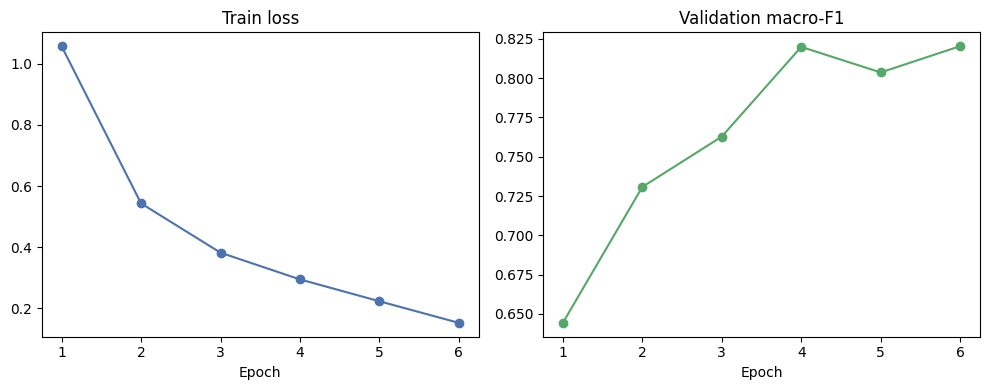

In [10]:
hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", color="#4C72B0")
axes[0].set_title("Train loss")
axes[0].set_xlabel("Epoch")
axes[1].plot(hist["epoch"], hist["macro_f1"], marker="o", color="#55A868")
axes[1].set_title("Validation macro-F1")
axes[1].set_xlabel("Epoch")
plt.tight_layout()
plt.show()


## 8. Evaluation

Same figures as the baseline: accuracy, macro precision, macro recall, macro-F1, then the per-class report and a row-normalised confusion matrix. Both validation and test numbers below are from the restored best epoch.


In [11]:
val_preds, val_proba = predict_proba(model, val_loader)
val_metrics = score(val_df["label"].to_numpy(), val_preds, "validation")


[validation] accuracy=0.8873  macro-P=0.8122  macro-R=0.8344  macro-F1=0.8204


In [12]:
test_preds, test_proba = predict_proba(model, test_loader)
test_metrics = score(test_df["label"].to_numpy(), test_preds, "test")
print()
print(classification_report(
    test_df["label"], test_preds,
    labels=list(range(len(label_names))),
    target_names=label_names,
    digits=3,
    zero_division=0,
))


[test] accuracy=0.8895  macro-P=0.8084  macro-R=0.8402  macro-F1=0.8203

              precision    recall  f1-score   support

      uchumi      0.673     0.816     0.738       467
     kitaifa      0.918     0.878     0.897      3348
     michezo      0.948     0.970     0.959      1996
   kimataifa      0.904     0.853     0.878       605
    burudani      0.936     0.872     0.903       703
        afya      0.472     0.653     0.548       219

    accuracy                          0.889      7338
   macro avg      0.808     0.840     0.820      7338
weighted avg      0.898     0.889     0.892      7338



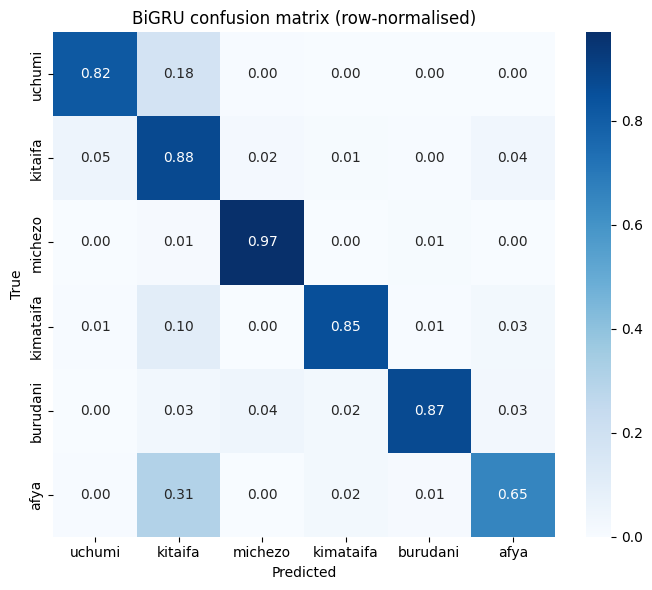

In [13]:
cm = confusion_matrix(test_df["label"], test_preds, labels=list(range(len(label_names))))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("BiGRU confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()


## 9. Error analysis

Misclassified test articles, sorted by how confident the model was when it was wrong. The `cause` column is left blank for the same hand labelling as the baseline (two topics in one article, mixed language, very short text, a doubtful label, rare topic words).


In [14]:
errors = test_df.copy()
errors["pred"]       = [label_names[i] for i in test_preds]
errors["confidence"] = test_proba.max(axis=1)
errors = errors[errors["label"] != test_preds].sort_values("confidence", ascending=False)
errors["cause"] = ""

print(f"{len(errors)} misclassified out of {len(test_df)} ({len(errors) / len(test_df):.1%})")

pd.set_option("display.max_colwidth", 300)
errors[["label_name", "pred", "confidence", "text"]].head(15)


811 misclassified out of 7338 (11.1%)


,label_name,pred,confidence,text
1471,kitaifa,afya,0.999968,"Na VERONICA ROMWALD – DAR ES SALAAM WATU wanane kati ya 100 nchini wana maambukizi ya virusi vya homa ya ini (Hepatit B), ambavyo vinatajwa kuwa hatari zaidi ya virusi vya Ukimwi (VVU). Uwezekano wa mtu kupata maambukizi ya virusi vya homa ya ini ikiwa atajamiiana na mtu mwenye virusi hivyo, ni..."
6060,kitaifa,afya,0.999875,"Aveline Kitomary – Dar es Salaam TAASISI ya\nTaifa ya Magonjwa ya Binadamu (NIMR), wanatarajia kuanza kufanya utafiti wa\nukubwa wa tatizo la nguvu za kiume katika sehemu mbalimbali nchini. Akizungumza\nna MTANZANIA katika mahojiano maalum,\nMkurugenzi wa Kuratibu na kukuza utafiti, Dk Paul Ka..."
5544,kitaifa,afya,0.999836,"\n\n \n\tNA VERONICA ROMWALD – DAR ES SALAAM\n \n\tWATU wanaougua ugonjwa sugu wa figo wana uwezekano mkubwa wa kushambuliwa na magonjwa ya akili kama sonona, wasiwasi na kuchanganyikiwa.\n \n\tHayo yamesemwa na Daktari Bingwa wa Afya na Magonjwa ya Akili wa Hospitali ya Taifa Muhimbili, Omar Ub..."
7206,kitaifa,kimataifa,0.999814,"NAIROBI, KENYA Rais Uhuru\nKenyatta wa Kenya amefutilia mbali mpango wowote wa kujumuishwa suala la ubaradhuli\nkama moja ya ajenda za Kongamano la Kimataifa la Idadi ya Watu litakalofanyika\nwiki hii katika mji mkuu wa nchi hiyo, Nairobi. Rais Kenyatta alisema\njana kuwa Kenya iko tayari kuwa m..."
632,kitaifa,afya,0.999710,Aveline Kitomary -Dar es salaam CHAMA cha Madaktari Tanzania (MAT) kimesema madaktari walioambukizwa virusi vya corona wamepona na kwamba maambukizi ya ugonjwa huo nchini yemepungua hadi kufikia asilimia 10 kulingana na sampuli za damu zilizopimwa kuanzia mwanzani mwa mwezi huu. Licha ya kutoa...
4061,kitaifa,afya,0.999657,"NA VERONICA ROMWALD – DAR ES SALAAM UGONJWA wa Saratani sasa ni tishio kwa Watanzania baada ya Shirika la Afya Duniani (WHO) kutoa takwimu zinazoonyesha kuwa kila mwaka karibu wagonjwa wapya 50,000 hugundulika kuwa na saratani za aina mbalimbali nchini. Takwimu hizo zimeonyesha kuwa kati ya wag..."
341,kitaifa,michezo,0.999401,"STAND United imepania ‘kufa’ n a Y anga katika mechi ya Ligi Kuu itakayochezwa kwenye uwanja wa Taifa Dar es Salaam, Jumapili ya wiki hii. Ligi hiyo inaendelea tena baada ya kusimama kwa takribani wiki mbili kuipisha timu ya taifa, Taifa Stars kucheza mechi ya kimataifa dhidi ya Uganda. Kocha m..."
3225,kitaifa,afya,0.999341,"Na VERONICA ROMWALD-DAR ES SALAAM UGONJWA wa homa ya dengue umeripotiwa kurejea nchini huku wagonjwa 11 kugundulika kuugua ugonjwa huo Dar es Salaam. Taarifa ya Wizara ya Afya, Jinsia, Maendeleo ya Jamii, Wazee na Watoto imeeleza kuwa homa ya ugonjwa huo imendulika baada ya wagonjwa kadhaa wa..."
2381,kitaifa,afya,0.999271,Na NORA DAMIAN-DAR ESSALAAM WATOTO wanaobalehe huenda wakaruhusiwa kupima virusi vya Ukimwi (VVU) ili kufikia malengo ya kutokomeza ugonjwa huo ifikapo mwaka 2030. Hayo ni miongoni mwa mapendekezo yaliyomo katika mwongozo wa uwekezaji kwenye Ukimwi ulioandaliwa na Tume ya Taifa ya Kudhibiti Uki...
1518,kitaifa,afya,0.999146,"NA VERONICA ROMWALD – DAR ES SALAAM BAADHI ya ndugu wa wagonjwa wanaokwenda kupatiwa matibabu katika Hospitali ya Taifa Muhimbili (MNH) wamelalamikia kuachiwa wasukume vitanda vya wagonjwa wao. Akizungumza na MTANZANIA jana, mmoja wa ndugu wenye wagonjwa wanaohudumiwa hospitalini hapo (jina lin..."


In [15]:
pairs = errors.groupby(["label_name", "pred"]).size().sort_values(ascending=False).head(10)
pairs


label_name  pred     
kitaifa     uchumi       173
            afya         123
uchumi      kitaifa       84
kitaifa     michezo       71
afya        kitaifa       67
kimataifa   kitaifa       63
burudani    michezo       31
kitaifa     kimataifa     29
michezo     kitaifa       27
burudani    kitaifa       22
dtype: int64

In [16]:
errors.to_csv(ERRORS_PATH, index=False)
print("Wrote", ERRORS_PATH)


Wrote bigru_errors.csv


## 10. Save

The checkpoint stores the trained embedding matrix, so a later app can load it without the fastText file. `bigru_metrics.json` holds accuracy, macro-F1, training time, and model size for the comparison table.

Reload with `torch.load("swahili_bigru.pt", map_location="cpu", weights_only=False)`.


In [17]:
cpu_state = {k: v.detach().cpu() for k, v in model.state_dict().items()}
torch.save(
    {
        "state_dict": cpu_state,
        "stoi": stoi,
        "label_names": label_names,
        "config": {
            "max_len": MAX_LEN,
            "embed_dim": EMBED_DIM,
            "hidden_dim": HIDDEN_DIM,
            "dropout": DROPOUT,
            "pad_idx": PAD,
            "unk_idx": UNK,
            "best_epoch": best_epoch,
        },
    },
    CKPT_PATH,
)

blob = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
assert blob["label_names"] == label_names
assert len(blob["stoi"]) == len(stoi)

ckpt_mb = CKPT_PATH.stat().st_size / 1e6
metrics = {
    "model": "fastText cc.sw.300 + BiGRU",
    "val": {k: round(v, 4) for k, v in val_metrics.items()},
    "test": {k: round(v, 4) for k, v in test_metrics.items()},
    "train_minutes": round(train_seconds / 60, 2),
    "best_epoch": best_epoch,
    "n_params": n_params,
    "checkpoint_mb": round(ckpt_mb, 2),
    "vocab_size": len(stoi),
    "max_len": MAX_LEN,
    "fasttext_token_coverage": round(ft_coverage, 4),
    "vocab_token_coverage": round(vocab_coverage, 4),
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2))
print(f"Saved {CKPT_PATH} ({ckpt_mb:.1f} MB, {n_params:,} parameters)")
print(json.dumps(metrics, indent=2))


Saved swahili_bigru.pt (56.7 MB, 13,936,182 parameters)
{
  "model": "fastText cc.sw.300 + BiGRU",
  "val": {
    "accuracy": 0.8873,
    "macro_p": 0.8122,
    "macro_r": 0.8344,
    "macro_f1": 0.8204
  },
  "test": {
    "accuracy": 0.8895,
    "macro_p": 0.8084,
    "macro_r": 0.8402,
    "macro_f1": 0.8203
  },
  "train_minutes": 41.6,
  "best_epoch": 6,
  "n_params": 13936182,
  "checkpoint_mb": 56.72,
  "vocab_size": 45348,
  "max_len": 256,
  "fasttext_token_coverage": 0.9226,
  "vocab_token_coverage": 0.9697
}


## 11. Quick try-out

The first sentence is the same one used in the baseline notebook. The second is a price story. The third is a health-ministry warning, which is the kind of article this model mixes up with national news.


In [18]:
def predict(text, k=3):
    ids = encode(clean_text(text), stoi, MAX_LEN)
    x = torch.tensor([ids], dtype=torch.long, device=device)
    lengths = torch.tensor([len(ids)])
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x, lengths), dim=-1)[0].cpu().numpy()
    top = np.argsort(p)[::-1][:k]
    return [(label_names[i], round(float(p[i]), 3)) for i in top]

examples = [
    "Timu ya taifa ya mpira wa miguu imeshinda mechi ya jana usiku",
    "Bei ya sukari na mafuta imepanda katika soko la dunia",
    "Wizara ya afya yatoa tahadhari kuhusu mlipuko wa ugonjwa",
]
for text in examples:
    print(text)
    print(" ", predict(text))


Timu ya taifa ya mpira wa miguu imeshinda mechi ya jana usiku


  [('michezo', 0.692), ('kitaifa', 0.305), ('kimataifa', 0.002)]
Bei ya sukari na mafuta imepanda katika soko la dunia


  [('uchumi', 0.986), ('kitaifa', 0.012), ('michezo', 0.001)]
Wizara ya afya yatoa tahadhari kuhusu mlipuko wa ugonjwa
  [('kitaifa', 0.897), ('afya', 0.061), ('kimataifa', 0.03)]


## 12. Download the results

Colab deletes the session disk when the runtime stops. This cell zips the checkpoint, the metrics, and the error sheet, then starts a browser download. A local run only writes the zip next to the notebook.


In [ ]:
import zipfile

bundle = RESULTS_DIR / "bigru_colab_outputs.zip"
names = [CKPT_PATH, METRICS_PATH, ERRORS_PATH, HISTORY_PATH]
with zipfile.ZipFile(bundle, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for path in names:
        if path.exists():
            z.write(path, path.name)
            print(f"  added {path.name}")
print(f"Wrote {bundle.resolve()} ({bundle.stat().st_size / 1e6:.1f} MB)")

try:
    from google.colab import files
except ImportError:
    print(f"Local run: the zip is in {RESULTS_DIR}.")
else:
    files.download(str(bundle))
